Loaded local file: diabetes_fixed.csv


Output()

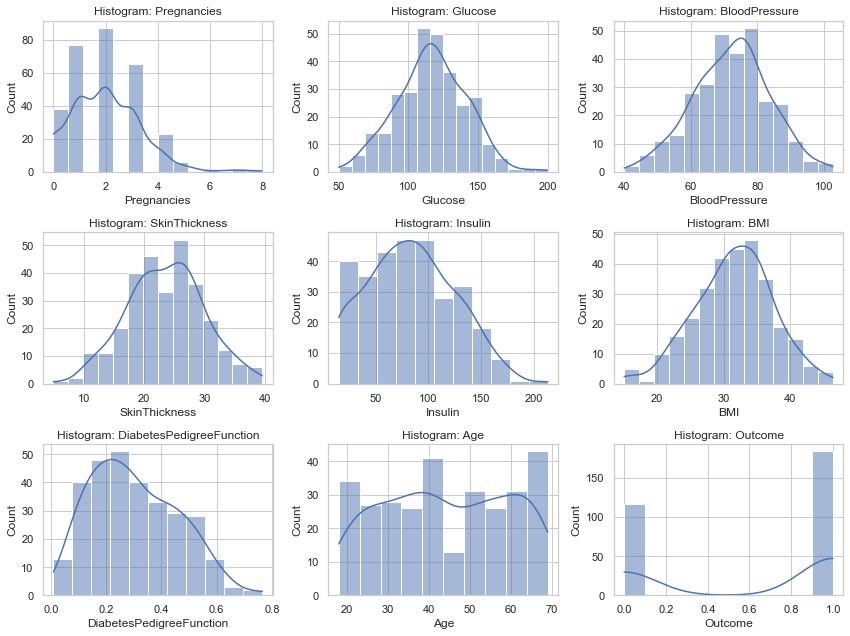

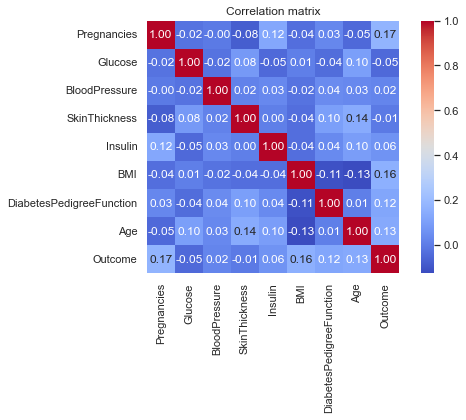

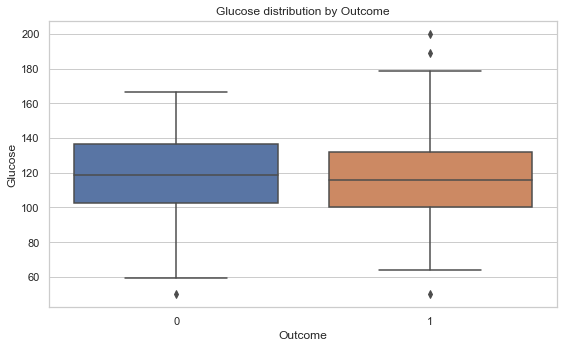

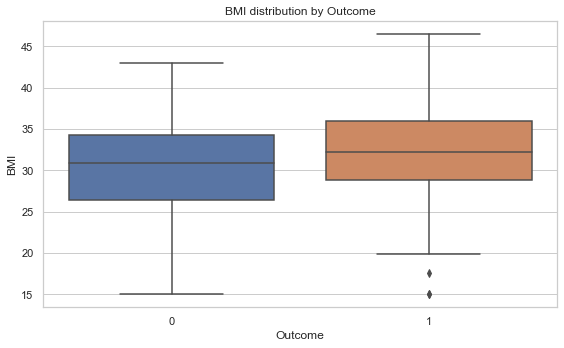

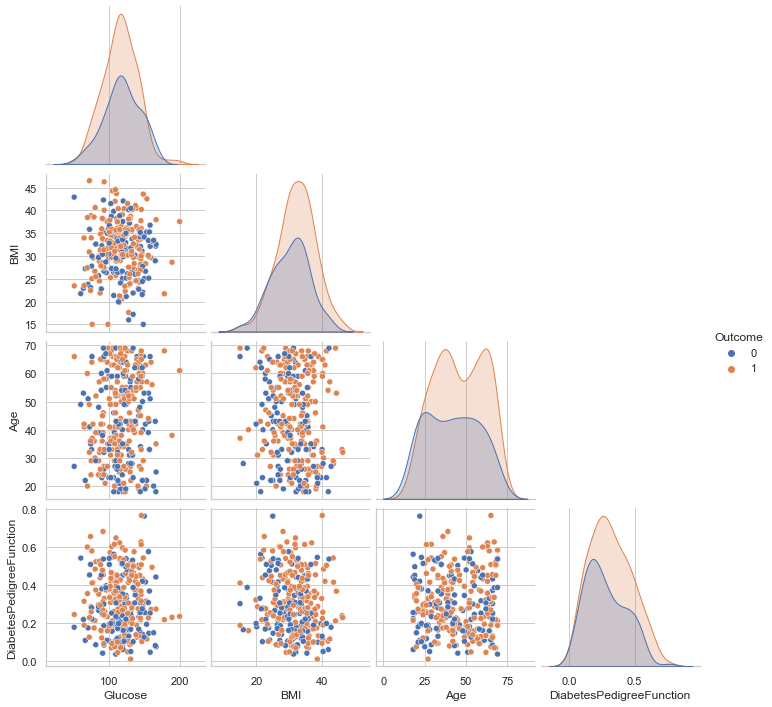

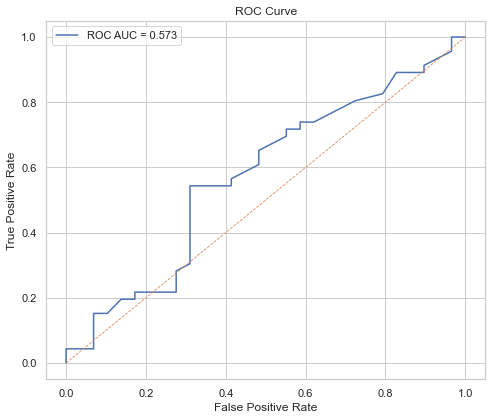

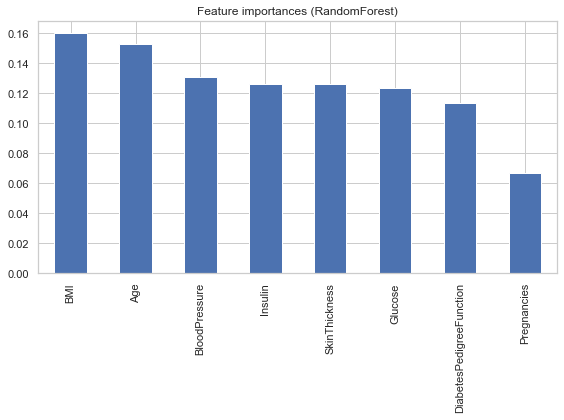

In [1]:
# -*- coding: utf-8 -*-
"""
Diabetes prediction app for Jupyter Notebook
- نسخة نهائية خالية من أخطاء global
- تشغيل في Jupyter: Shift+Enter
مكتبات مطلوبة: pandas, numpy, matplotlib, seaborn, scikit-learn, ipywidgets
إذا لم تكن مثبتة نفّذ في خلية منفصلة:
!pip install pandas numpy matplotlib seaborn scikit-learn ipywidgets
ثم فعّل widgets إن لزم:
!jupyter nbextension enable --py widgetsnbextension
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, roc_curve, classification_report
)

import ipywidgets as widgets
from IPython.display import display, clear_output

sns.set(style="whitegrid")

# ------------------ App class to encapsulate state ------------------
class DiabetesApp:
    def __init__(self, csv_path='diabetes_fixed.csv'):
        # Load data (or create synthetic if file missing)
        self.csv_path = csv_path
        self.df = self._load_dataset(csv_path)
        # Ensure columns are standardized
        self.feature_cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
        expected = self.feature_cols + ['Outcome']
        missing = [c for c in expected if c not in self.df.columns]
        if missing:
            raise ValueError(f"ملف البيانات يفتقد الأعمدة التالية: {missing}. تأكد من وجود الأعمدة: {expected}")
        # Model & state
        self.pipeline = self._build_pipeline()
        self.metrics = {}
        self.X_train = self.X_test = self.y_train = self.y_test = None
        self.y_pred = None
        self.y_proba = None
        self.importances = None
        # Train initial model
        self.train_model()
        # Build UI
        self._build_widgets()
    
    def _load_dataset(self, path):
        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"Loaded local file: {path}")
        else:
            print(f"File '{path}' not found. Creating synthetic dataset as fallback.")
            rng = np.random.RandomState(0)
            n = 500
            df = pd.DataFrame({
                'Pregnancies': rng.poisson(2, n),
                'Glucose': rng.normal(120, 30, n).clip(50, 200),
                'BloodPressure': rng.normal(70, 12, n).clip(30, 120),
                'SkinThickness': rng.normal(20, 8, n).clip(5, 55),
                'Insulin': rng.normal(80, 40, n).clip(15, 400),
                'BMI': rng.normal(32, 7, n).clip(15, 60),
                'DiabetesPedigreeFunction': rng.beta(2, 5, n),
                'Age': rng.randint(18, 80, n),
            })
            prob = (0.002*(df['Glucose']-100) + 0.02*(df['BMI']-25) + 0.01*(df['Age']-30) + df['DiabetesPedigreeFunction'])
            prob = 1/(1+np.exp(-prob))
            df['Outcome'] = (rng.rand(n) < prob).astype(int)
        # normalize column names
        df.columns = [c.strip() for c in df.columns]
        return df

    def _build_pipeline(self):
        pipe = Pipeline([
            ('impute', SimpleImputer(strategy='mean')),
            ('scale', StandardScaler()),
            ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
        ])
        return pipe

    def train_model(self, test_size=0.25):
        X = self.df[self.feature_cols]
        y = self.df['Outcome']
        # handle case where y has only one class (rare with synthetic data)
        if len(np.unique(y)) < 2:
            raise ValueError("Target variable 'Outcome' يجب أن يحتوي على قيمتين (0 و 1) لتدريب النموذج.")
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=42
        )
        self.pipeline.fit(self.X_train, self.y_train)
        self.y_pred = self.pipeline.predict(self.X_test)
        self.y_proba = self.pipeline.predict_proba(self.X_test)[:,1]
        # metrics
        self.metrics['accuracy'] = accuracy_score(self.y_test, self.y_pred)
        self.metrics['precision'] = precision_score(self.y_test, self.y_pred, zero_division=0)
        self.metrics['recall'] = recall_score(self.y_test, self.y_pred, zero_division=0)
        self.metrics['roc_auc'] = roc_auc_score(self.y_test, self.y_proba)
        # feature importances
        rf = self.pipeline.named_steps['rf']
        self.importances = pd.Series(rf.feature_importances_, index=self.feature_cols).sort_values(ascending=False)
    
    # ------------------ Plotting functions ------------------
    def plot_histograms(self, ax_rows=3, ax_cols=3):
        cols = self.feature_cols + ['Outcome']
        nplots = min(len(cols), ax_rows*ax_cols)
        fig, axes = plt.subplots(ax_rows, ax_cols, figsize=(12, 9))
        axes = axes.flatten()
        for i in range(nplots):
            col = cols[i]
            sns.histplot(self.df[col], kde=True, ax=axes[i])
            axes[i].set_title(f'Histogram: {col}')
        for j in range(nplots, len(axes)):
            fig.delaxes(axes[j])
        plt.tight_layout()
        return fig

    def plot_corr_heatmap(self):
        corr = self.df[self.feature_cols + ['Outcome']].corr()
        fig = plt.figure(figsize=(8,6))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True)
        plt.title('Correlation matrix')
        plt.tight_layout()
        return fig

    def plot_boxplots(self):
        figs = []
        for col in ['Glucose','BMI']:
            fig = plt.figure(figsize=(8,5))
            sns.boxplot(data=self.df, x='Outcome', y=col)
            plt.title(f'{col} distribution by Outcome')
            plt.tight_layout()
            figs.append(fig)
        return figs

    def plot_pairplot(self):
        subset = ['Glucose','BMI','Age','DiabetesPedigreeFunction','Outcome']
        try:
            g = sns.pairplot(self.df[subset], hue='Outcome', corner=True)
            return g
        except Exception as e:
            print("Pairplot failed:", e)
            return None

    def plot_roc_curve(self):
        fig = plt.figure(figsize=(7,6))
        fpr, tpr, _ = roc_curve(self.y_test, self.y_proba)
        plt.plot(fpr, tpr, label=f'ROC AUC = {self.metrics["roc_auc"]:.3f}')
        plt.plot([0,1],[0,1],'--', linewidth=0.8)
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curve')
        plt.legend()
        plt.tight_layout()
        return fig

    def plot_feature_importance(self):
        fig = plt.figure(figsize=(8,6))
        self.importances.plot(kind='bar')
        plt.title('Feature importances (RandomForest)')
        plt.tight_layout()
        return fig

    # ------------------ UI build ------------------
    def _build_widgets(self):
        # Output areas
        self.info_out = widgets.Output()
        self.table_out = widgets.Output()
        self.plot_out = widgets.Output()
        self.add_out = widgets.Output()
        self.export_out = widgets.Output()
        
        # Buttons
        self.info_button = widgets.Button(description="Show dataset info", button_style='info')
        self.info_button.on_click(self.on_info_clicked)

        self.table_button = widgets.Button(description="Show data sample (10 rows)", button_style='primary')
        self.table_button.on_click(self.on_table_clicked)

        self.plot_button = widgets.Button(description="Show analysis plots", button_style='warning')
        self.plot_button.on_click(self.on_plot_clicked)

        self.export_button = widgets.Button(description="Export current data to CSV", button_style='')
        self.export_button.on_click(self.on_export_clicked)

        # Input form widgets for adding patient
        self.form_items = {}
        for col in self.feature_cols:
            if col in ['Pregnancies','Age']:
                self.form_items[col] = widgets.IntText(description=col, value=int(self.df[col].median()))
            else:
                # set reasonable decimals
                self.form_items[col] = widgets.FloatText(description=col, value=float(self.df[col].median()))
        self.add_button = widgets.Button(description="Add patient & predict", button_style='success')
        self.add_button.on_click(self.on_add_clicked)

        # Build tab layout
        tab_children = []
        tab_children.append(widgets.VBox([widgets.Label('Dataset details'), self.info_button, self.info_out]))
        tab_children.append(widgets.VBox([widgets.Label('Data sample'), self.table_button, self.table_out]))
        tab_children.append(widgets.VBox([widgets.Label('Analysis & Plots'), self.plot_button, self.plot_out]))
        form_box = widgets.VBox(list(self.form_items.values()) + [self.add_button, self.add_out])
        tab_children.append(widgets.VBox([widgets.Label('Add new patient'), form_box]))
        tab_children.append(widgets.VBox([widgets.Label('Export'), self.export_button, self.export_out]))

        self.ui = widgets.Tab()
        self.ui.children = tab_children
        self.ui.set_title(0, 'Info')
        self.ui.set_title(1, 'Sample')
        self.ui.set_title(2, 'Plots')
        self.ui.set_title(3, 'Add Data')
        self.ui.set_title(4, 'Export')
        display(self.ui)

        # initial message
        self.status_out = widgets.Output()
        with self.status_out:
            print("Ready. استخدم التبويبات (Tabs) لعرض المعلومات، الرسومات، وإضافة بيانات جديدة.")
        display(self.status_out)

    # ------------------ Callbacks ------------------
    def on_info_clicked(self, b):
        with self.info_out:
            clear_output()
            print("شكل البيانات (rows, columns):", self.df.shape)
            print("\nالأعمدة:\n", list(self.df.columns))
            print("\nأنواع الأعمدة:\n", self.df.dtypes.to_dict())
            print("\nقيم مفقودة في كل عمود:\n", self.df.isnull().sum().to_dict())
            print("\nإحصاءات وصفية (ملخص):")
            display(self.df.describe().T.round(3))

    def on_table_clicked(self, b):
        with self.table_out:
            clear_output()
            display(self.df.sample(10).reset_index(drop=True))

    def on_plot_clicked(self, b):
        with self.plot_out:
            clear_output()
            print("Generating plots and evaluation...")
            # 1 histograms
            fig1 = self.plot_histograms()
            display(fig1)
            # 2 corr heatmap
            fig2 = self.plot_corr_heatmap()
            display(fig2)
            # 3 boxplots
            figs_box = self.plot_boxplots()
            for f in figs_box:
                display(f)
            # 4 pairplot
            pair = self.plot_pairplot()
            if pair is not None:
                display(pair)
            # 5 ROC
            fig_roc = self.plot_roc_curve()
            display(fig_roc)
            # 6 feature importance
            fig_imp = self.plot_feature_importance()
            display(fig_imp)

            # Model metrics and report
            print("\nModel evaluation on held-out test set:")
            for k,v in self.metrics.items():
                print(f"{k}: {v:.3f}")
            print("\nClassification report on test set:")
            print(classification_report(self.y_test, self.y_pred, zero_division=0))

    def on_add_clicked(self, b):
        with self.add_out:
            clear_output()
            # read new patient values
            new_values = {col: self.form_items[col].value for col in self.feature_cols}
            new_df = pd.DataFrame([new_values])
            # Predict
            try:
                prob = self.pipeline.predict_proba(new_df)[0,1]
                pred = int(self.pipeline.predict(new_df)[0])
            except Exception as e:
                print("خطأ في التنبؤ:", e)
                return
            # Append to df with predicted label (for convenience)
            appended = new_df.copy()
            appended['Outcome'] = pred
            # Update dataframe attribute
            self.df = pd.concat([self.df, appended], ignore_index=True)
            print("تمت إضافة المريض الجديد (التسمية المخزنة هي التنبؤ).")
            print(f"Predicted probability of diabetes: {prob:.3f}")
            print(f"Predicted class: {pred}")
            # Retrain model on updated data
            try:
                self.train_model()
                print("تمت إعادة تدريب النموذج على البيانات المحدثة.")
                print("\nUpdated metrics:")
                for k,v in self.metrics.items():
                    print(f"{k}: {v:.3f}")
            except Exception as e:
                print("خطأ أثناء إعادة التدريب:", e)

    def on_export_clicked(self, b):
        with self.export_out:
            clear_output()
            out_path = 'diabetes_updated.csv'
            self.df.to_csv(out_path, index=False)
            print(f"Saved current dataframe to '{out_path}' in the notebook working directory.")

# ------------------ Instantiate and run the app ------------------
# إذا أردت استخدام ملف آخر اكتب مسار الملف في الوسيط بين القوسين
app = DiabetesApp(csv_path='diabetes_fixed.csv')

# انتهى الكود - الآن استخدم الواجهة الظاهرة في النوتبوك